# 13 – Clean AI-generated PR dataset (all sources)
**One row = one AI-generated PR**, no duplicates, same columns for every source.

| Source | What it adds |
|---|---|
| AIDev v4 `all_pull_request` | 2.74M AI PRs, 6 agents, up to Oct 2025 (the base) |
| AIDev v4 `pull_request` (AIDev-pop v4) | flag: PR has commit details (changed files) in v4 |
| AIDev-pop 2025 (`10_Build_AI_PRs_Dataset`) | task type (fix, feat…), papers that use the PR, *fixed later* (Who Finishes, Khemissi), PRs deleted from v4 |
| Watanabe 2025 | Claude Code PRs not in AIDev |
| Xia & Miller, Sawada, Yu | **not added**: commits / files, not PRs |

Output → `data/AI_PRS_CLEAN/`: `AI_PRS_CLEAN_ALL.parquet`, `AI_PRS_CLEAN_PYTHON.parquet` + `.csv`, `AI_PRS_CLEAN_SUMMARY.xlsx`.

In [1]:
import sys, os
sys.path.insert(0, "../..")
from common import *
D = os.path.join("..", "..", "..", "data")
OUT = os.path.join(D, "AI_PRS_CLEAN"); os.makedirs(OUT, exist_ok=True)
RAW = r"C:\Users\GIGABYTE\Desktop\code_theis\evolution-assurance\data\raw"   # <- AIDev v4 folder
COLS = ["pr_url", "pr_id", "agent", "repo", "language", "stars", "title", "state", "outcome",
        "created_at", "merged_at", "closed_at", "source", "in_aidev_v4", "in_aidev_v4_pop", "in_aidev_pop_2025",
        "task_type", "in_papers", "fixed_later", "fixed_later_source", "is_python"]
def outcome(df):
    return np.where(df.merged_at.notna(), "merged", np.where(df.state.astype(str).str.lower().eq("open"), "open", "closed"))
import numpy as np

## 1. AIDev v4 – all AI PRs (base)

In [2]:
v4 = pd.read_parquet(os.path.join(RAW, "all_pull_request.parquet"),
                     columns=["id", "html_url", "agent", "title", "state", "created_at", "closed_at", "merged_at", "repo_url"])
v4["agent"] = v4["agent"].map(agent_of)
rp = pd.read_parquet(os.path.join(RAW, "all_repository.parquet"), columns=["url", "full_name", "language", "stars"])
v4 = v4.merge(rp.drop_duplicates("url").rename(columns={"url": "repo_url", "full_name": "repo"}), on="repo_url", how="left")
pop4 = pd.read_parquet(os.path.join(RAW, "pull_request.parquet"), columns=["html_url"])
v4 = v4.rename(columns={"id": "pr_id", "html_url": "pr_url"})
v4["source"] = "AIDev v4"
v4["in_aidev_v4"] = True
v4["in_aidev_v4_pop"] = v4.pr_url.isin(pop4.html_url)
print(f"AIDev v4: {len(v4):,} AI PRs | in AIDev-pop v4 (with changed files): {v4.in_aidev_v4_pop.sum():,}")

AIDev v4: 2,743,854 AI PRs | in AIDev-pop v4 (with changed files): 71,677


## 2. AIDev-pop 2025 + paper labels (from notebook 10)

In [3]:
old = pd.read_csv(os.path.join(D, "AI_PRS_DATASET", "AI_PRS_DATASET.csv"), low_memory=False)
old_pop = old[old.source == "AIDev-pop"]
lab = old_pop.set_index("pr_url")[["task_type", "in_papers", "fixed_later", "fixed_later_source"]]
v4 = v4.join(lab, on="pr_url")
v4["in_aidev_pop_2025"] = v4.pr_url.isin(old_pop.pr_url)
extra = old_pop[~old_pop.pr_url.isin(v4.pr_url)].copy()          # in AIDev-pop 2025 but gone from v4
extra = extra.assign(source="AIDev-pop 2025 (not in v4)", in_aidev_v4=False, in_aidev_v4_pop=False, in_aidev_pop_2025=True)
print(f"AIDev-pop 2025 PRs found in v4: {v4.in_aidev_pop_2025.sum():,} | missing from v4 (added): {len(extra):,}")

AIDev-pop 2025 PRs found in v4: 33,159 | missing from v4 (added): 437


## 3. Watanabe – Claude Code PRs

In [4]:
W = os.path.join(D, "04_Watanabe_ClaudeCode", "ontheuseofagenticcoding", "Data")
w = pd.concat([pd.read_csv(os.path.join(W, f"APR-{x}.csv")).assign(state=x.lower()) for x in ["MERGED", "OPEN", "CLOSED"]])
w = w.drop_duplicates("url")
v4.loc[v4.pr_url.isin(w.url), "in_papers"] = v4.loc[v4.pr_url.isin(w.url), "in_papers"].fillna("").str.cat(["Watanabe"] * v4.pr_url.isin(w.url).sum(), sep=", ").str.strip(", ")
wn = w[~w.url.isin(v4.pr_url) & ~w.url.isin(extra.pr_url)]
lang = rp.drop_duplicates("full_name").set_index("full_name")["language"]
wn = pd.DataFrame({"pr_url": wn.url, "agent": "Claude Code", "repo": wn.owner + "/" + wn.repo_name,
                   "stars": wn.stars, "state": wn.state, "created_at": wn.created_at, "merged_at": wn.get("merged_at"),
                   "source": "Watanabe 2025", "in_aidev_v4": False, "in_aidev_v4_pop": False, "in_aidev_pop_2025": False,
                   "in_papers": "Watanabe"})
wn["language"] = wn.repo.map(lang)
print(f"Watanabe: {len(w):,} PRs | already in AIDev v4: {w.url.isin(v4.pr_url).sum():,} | added: {len(wn):,}")

Watanabe: 797 PRs | already in AIDev v4: 92 | added: 705


## 4. Merge, clean, remove duplicates

In [5]:
ai = pd.concat([v4, extra, wn], ignore_index=True)
ai = ai.drop_duplicates("pr_url", keep="first")
for c in ["created_at", "merged_at", "closed_at"]:
    ai[c] = pd.to_datetime(ai[c], errors="coerce", utc=True, format="mixed")
ai["merged_at"] = ai["merged_at"].where(~(ai.state.astype(str).str.lower().eq("merged") & ai.merged_at.isna()), ai["closed_at"])
ai["outcome"] = outcome(ai)
ai["is_python"] = ai.language.eq("Python")
ai["fixed_later"] = ai.fixed_later.fillna(False).astype(bool)
ai["in_papers"] = ai.in_papers.fillna("")
ai = ai[COLS].sort_values("created_at").reset_index(drop=True)
print(f"CLEAN dataset: {len(ai):,} AI PRs | {ai.repo.nunique():,} repos | "
      f"{ai.created_at.min():%Y-%m-%d} -> {ai.created_at.max():%Y-%m-%d} | Python: {ai.is_python.sum():,}")
overview(ai, "Clean AI PR dataset", n=3)

CLEAN dataset: 2,744,996 AI PRs | 326,974 repos | 2024-12-24 -> 2025-10-24 | Python: 688,006


**Clean AI PR dataset** — **2,744,996 rows × 21 columns** (783.4 MB in memory)

*First 3 lines:*

,pr_url,pr_id,agent,repo,language,stars,title,state,outcome,created_at,merged_at,closed_at,source,in_aidev_v4,in_aidev_v4_pop,in_aidev_pop_2025,task_type,in_papers,fixed_later,fixed_later_source,is_python
0,https://github.com/AgentOps-AI/agentops/pull/603,2.756922e+09,Devin,AgentOps-AI/agentops,Python,4989.0,Add LLM Integration Tests,closed,closed,2024-12-24 00:23:09+00:00,NaT,2025-01-09 11:13:02+00:00,AIDev v4,True,True,True,test,,False,NaN,True
1,https://github.com/zkemail/archive.zk.email/pull/139,2.756955e+09,Devin,zkemail/archive.zk.email,TypeScript,12.0,feat: implement DNS query checking upon archive get (#130),closed,closed,2024-12-24 00:57:04+00:00,NaT,2025-01-23 18:39:40+00:00,AIDev v4,True,False,False,NaN,,False,NaN,False
2,https://github.com/flyby-yunakayama/network-simulator/pu...,2.757009e+09,Devin,flyby-yunakayama/network-simulator,Python,14.0,fix: remove duplicate DHCP and DNS assignment logs,closed,merged,2024-12-24 01:42:40+00:00,2024-12-24 01:50:22+00:00,2024-12-24 01:50:22+00:00,AIDev v4,True,False,False,NaN,,False,NaN,True


*All columns:*

,column,type,missing_%,unique,example
0,pr_url,str,0.0,2744996,https://github.com/AgentOps-AI/agentops/pull/603
1,pr_id,float64,0.0,2743911,2756921963.0
2,agent,str,0.0,6,Devin
3,repo,str,0.3,326974,AgentOps-AI/agentops
4,language,str,3.6,327,Python
5,stars,float64,0.3,3253,4989.0
6,title,str,0.0,2547637,Add LLM Integration Tests
7,state,str,0.0,3,closed
8,outcome,str,0.0,3,closed
9,created_at,"datetime64[us, UTC]",0.0,2449853,2024-12-24 00:23:09+00:00


,column,type,missing_%,unique,example
0,pr_url,str,0.0,2744996,https://github.com/AgentOps-AI/agentops/pull/603
1,pr_id,float64,0.0,2743911,2756921963.0
2,agent,str,0.0,6,Devin
3,repo,str,0.3,326974,AgentOps-AI/agentops
4,language,str,3.6,327,Python
5,stars,float64,0.3,3253,4989.0
6,title,str,0.0,2547637,Add LLM Integration Tests
7,state,str,0.0,3,closed
8,outcome,str,0.0,3,closed
9,created_at,"datetime64[us, UTC]",0.0,2449853,2024-12-24 00:23:09+00:00


## 5. Tables

In [6]:
src = ai.groupby("source").agg(AI_PRs=("pr_url", "size"), python=("is_python", "sum"),
                               first=("created_at", "min"), latest=("created_at", "max"))
src["first"] = src["first"].dt.date; src["latest"] = src["latest"].dt.date
display(src)
per = ai.groupby("agent").agg(AI_PRs=("pr_url", "size"), merged=("outcome", lambda s: (s == "merged").sum()),
                              python=("is_python", "sum"), python_merged=("is_python", lambda s: (s & (ai.loc[s.index, "outcome"] == "merged")).sum()),
                              in_v4_pop=("in_aidev_v4_pop", "sum"), with_task_type=("task_type", "count"),
                              fixed_later=("fixed_later", "sum")).sort_values("AI_PRs", ascending=False)
per.loc["TOTAL"] = per.sum()
display(per)
pp = ai[ai.is_python & ai.outcome.eq("merged")]
print(f"Python + merged (what linker.py checks): {len(pp):,} AI PRs in {pp.repo.nunique():,} repos")

,AI_PRs,python,first,latest
source,,,,
AIDev v4,2743854,687771,2024-12-24,2025-10-24
AIDev-pop 2025 (not in v4),437,142,2025-02-07,2025-07-30
Watanabe 2025,705,93,2025-02-21,2025-04-30


,AI_PRs,merged,python,python_merged,in_v4_pop,with_task_type,fixed_later
agent,,,,,,,
Codex,2069787,1792598,564880,505444,35521,21799,451
Copilot,349730,222213,65722,45460,23496,4971,106
Cursor,212606,115149,33913,20778,4059,1539,90
Jules,50490,38691,11556,9482,487,0,0
Devin,43436,26985,7608,5135,6172,4829,269
Claude Code,18947,15234,4327,3494,1942,458,32
TOTAL,2744996,2210870,688006,589793,71677,33596,948


Python + merged (what linker.py checks): 589,793 AI PRs in 48,357 repos


## 6. Charts

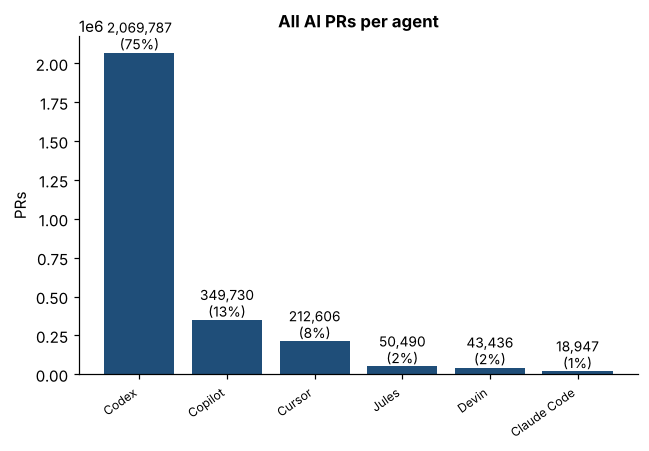

*Exact numbers – All AI PRs per agent*

,number,%
agent,,
Codex,2069787.0,75.4
Copilot,349730.0,12.7
Cursor,212606.0,7.7
Jules,50490.0,1.8
Devin,43436.0,1.6
Claude Code,18947.0,0.7
TOTAL,2744996.0,100.0


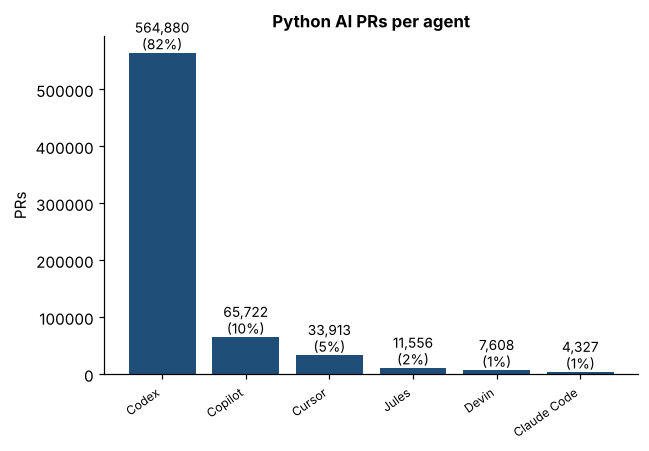

*Exact numbers – Python AI PRs per agent*

,number,%
agent,,
Codex,564880.0,82.1
Copilot,65722.0,9.6
Cursor,33913.0,4.9
Jules,11556.0,1.7
Devin,7608.0,1.1
Claude Code,4327.0,0.6
TOTAL,688006.0,100.0


/tmp/ipykernel_585/3375137004.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  m = ai[ai.is_python].groupby(ai.created_at.dt.to_period("M").astype(str)).size()


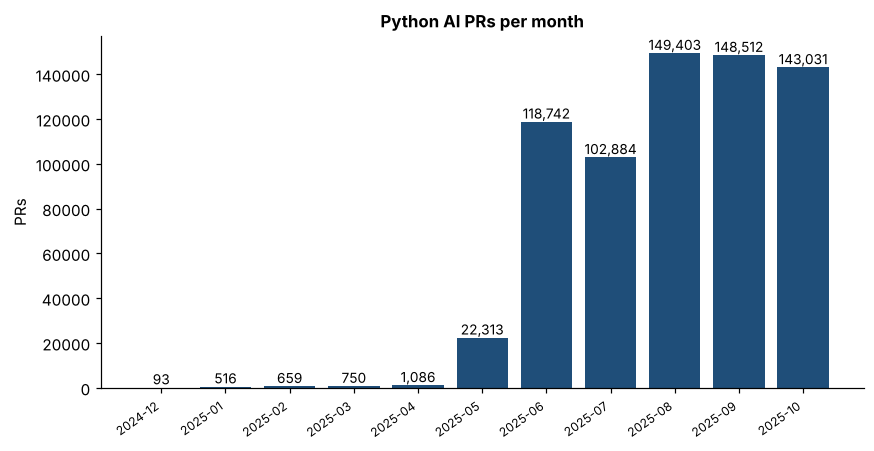

*Exact numbers – Python AI PRs per month*

,number,%
created_at,,
2024-12,93.0,0.0
2025-01,516.0,0.1
2025-02,659.0,0.1
2025-03,750.0,0.1
2025-04,1086.0,0.2
2025-05,22313.0,3.2
2025-06,118742.0,17.3
2025-07,102884.0,15.0
2025-08,149403.0,21.7


In [7]:
bar(ai.agent.value_counts(), "All AI PRs per agent", "1_ai_prs_per_agent.png", "PRs", pct=True)
bar(ai[ai.is_python].agent.value_counts(), "Python AI PRs per agent", "2_python_per_agent.png", "PRs", pct=True)
m = ai[ai.is_python].groupby(ai.created_at.dt.to_period("M").astype(str)).size()
bar(m, "Python AI PRs per month", "3_python_per_month.png", "PRs")

## 7. Save

In [8]:
ai.to_parquet(os.path.join(OUT, "AI_PRS_CLEAN_ALL.parquet"), index=False)
py = ai[ai.is_python]
py.to_parquet(os.path.join(OUT, "AI_PRS_CLEAN_PYTHON.parquet"), index=False)
py.to_csv(os.path.join(OUT, "AI_PRS_CLEAN_PYTHON.csv"), index=False)
with pd.ExcelWriter(os.path.join(OUT, "AI_PRS_CLEAN_SUMMARY.xlsx")) as xw:
    pd.DataFrame({"column": COLS}).to_excel(xw, sheet_name="Columns", index=False)
    src.to_excel(xw, sheet_name="Per source")
    per.to_excel(xw, sheet_name="Per agent")
    smp = py.sample(min(1000, len(py)), random_state=1).copy()
    for c in ["created_at", "merged_at", "closed_at"]:
        smp[c] = smp[c].dt.tz_localize(None)
    smp.to_excel(xw, sheet_name="Python sample (1000)", index=False)
for f in sorted(os.listdir(OUT)):
    print(f"{f:32s} {os.path.getsize(os.path.join(OUT, f)) / 1e6:8.1f} MB")

AI_PRS_CLEAN_ALL.parquet            222.4 MB
AI_PRS_CLEAN_PYTHON.csv             192.0 MB
AI_PRS_CLEAN_PYTHON.parquet          50.5 MB
AI_PRS_CLEAN_SUMMARY.xlsx             0.2 MB
